# House-price valuation model (Ames, Iowa)
An automated valuation model for 2,930 residential sales with 80 property attributes. It compares regularised linear models with gradient boosting under **5-fold cross-validation**, reports error in dollars, and explains which features drive value.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance
h = pd.read_csv("data/ames_housing.csv")
# De Cock (2011), the dataset's author, recommends removing the five houses over 4,000 sq ft (partial / unusual sales)
h = h[h["Gr Liv Area"] < 4000].drop(columns=["Order", "PID"])
h["Total SF"] = h["Total Bsmt SF"].fillna(0) + h["1st Flr SF"] + h["2nd Flr SF"]
h["Age"] = h["Yr Sold"] - h["Year Built"]; h["Years Since Remod"] = h["Yr Sold"] - h["Year Remod/Add"]
y, X = h.pop("SalePrice"), h
print(f"{len(X):,} sales, {X.shape[1]} features, median price ${y.median():,.0f}")

2,925 sales, 84 features, median price $160,000


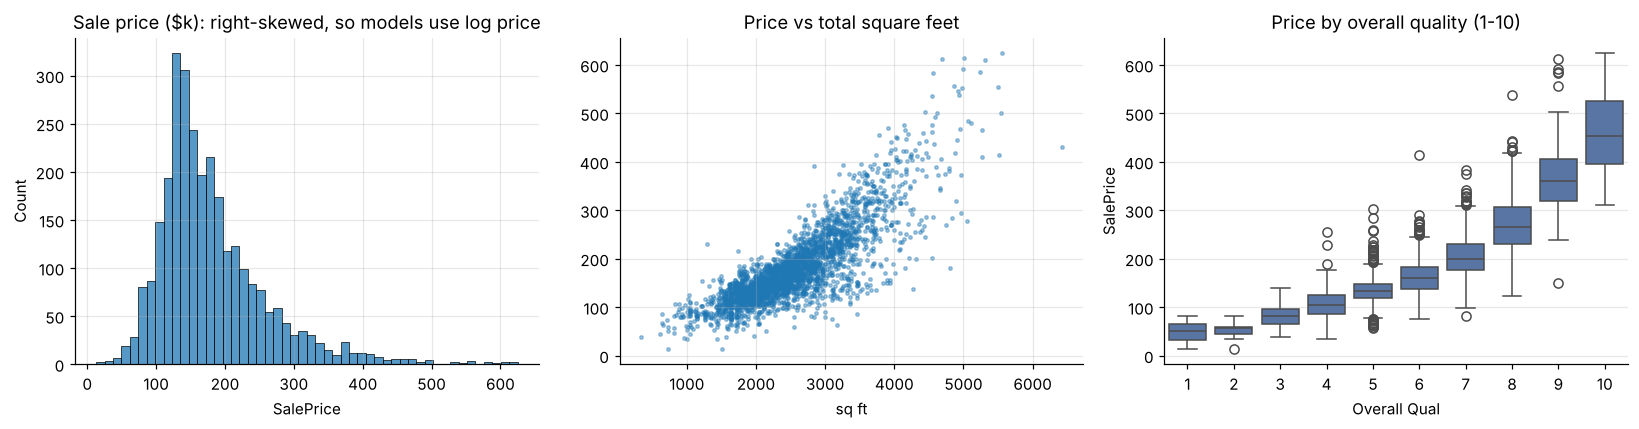

In [2]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(y / 1000, ax=ax[0], bins=50); ax[0].set_title("Sale price ($k): right-skewed, so models use log price")
ax[1].scatter(X["Total SF"], y / 1000, s=5, alpha=0.4); ax[1].set_title("Price vs total square feet"); ax[1].set_xlabel("sq ft")
sns.boxplot(x=X["Overall Qual"], y=y / 1000, ax=ax[2], color="#4C72B0"); ax[2].set_title("Price by overall quality (1-10)")
fig.tight_layout(); plt.savefig(IMG / "eda.png", bbox_inches="tight"); plt.show()

In [3]:
num = X.select_dtypes("number").columns.tolist(); cat = X.columns.difference(num).tolist()
prep = ColumnTransformer([("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num),
                          ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False)), cat)])
log_target = lambda est: TransformedTargetRegressor(est, func=np.log, inverse_func=np.exp)
models = {"Ridge": log_target(make_pipeline(prep, RidgeCV(alphas=np.logspace(-1, 3, 30)))),
          "Lasso": log_target(make_pipeline(prep, LassoCV(alphas=np.logspace(-4.5, -1, 40), max_iter=5000, cv=5, random_state=0))),
          "Gradient boosting": log_target(make_pipeline(prep, HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=24, random_state=0)))}
cv = KFold(5, shuffle=True, random_state=42)
preds = {k: cross_val_predict(m, X, y, cv=cv) for k, m in models.items()}
preds["Ensemble (avg)"] = np.mean([preds["Ridge"], preds["Gradient boosting"]], axis=0)
res = pd.DataFrame({k: {"MAE ($)": mean_absolute_error(y, p), "median abs. % error": np.median(np.abs(p / y - 1)) * 100,
                        "within 10% of price": (np.abs(p / y - 1) < 0.10).mean() * 100, "R²": r2_score(y, p)} for k, p in preds.items()}).T
res.style.format({"MAE ($)": "{:,.0f}", "median abs. % error": "{:.1f}%", "within 10% of price": "{:.0f}%", "R²": "{:.3f}"})

,MAE ($),median abs. % error,within 10% of price,R²
Ridge,"13,009",5.4%,75%,0.940
Lasso,"13,035",5.5%,74%,0.939
Gradient boosting,"13,403",5.4%,74%,0.933
Ensemble (avg),"12,274",5.0%,78%,0.945


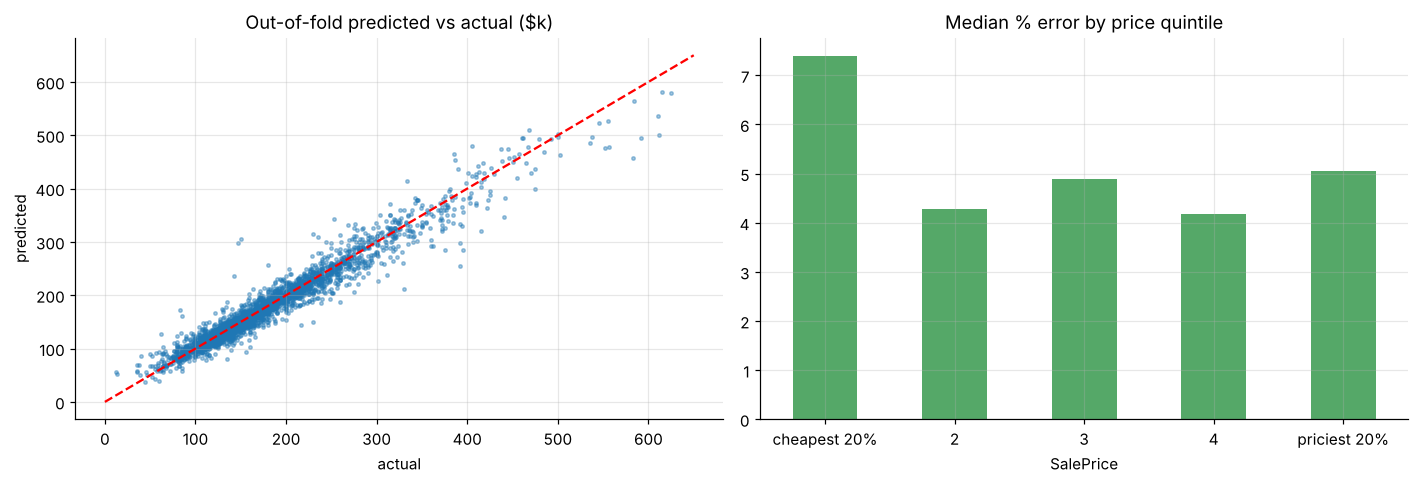

In [4]:
p = preds["Ensemble (avg)"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].scatter(y / 1000, p / 1000, s=5, alpha=0.4); ax[0].plot([0, 650], [0, 650], "r--"); ax[0].set_title("Out-of-fold predicted vs actual ($k)"); ax[0].set_xlabel("actual"); ax[0].set_ylabel("predicted")
err = pd.Series(np.abs(p / y - 1), index=X.index)
err.groupby(pd.qcut(y, 5, labels=["cheapest 20%", "2", "3", "4", "priciest 20%"])).median().mul(100).plot.bar(ax=ax[1], color="#55A868", rot=0)
ax[1].set_title("Median % error by price quintile"); fig.tight_layout(); plt.savefig(IMG / "valuation_accuracy.png", bbox_inches="tight"); plt.show()

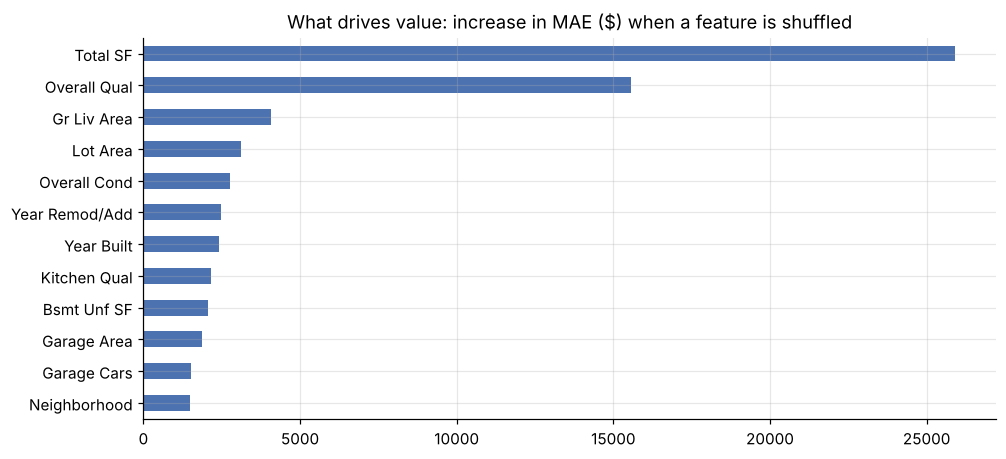

In [5]:
gb = models["Gradient boosting"].fit(X, y)
sample = X.sample(800, random_state=0)
imp = permutation_importance(gb, sample, y.loc[sample.index], n_repeats=5, random_state=0, scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean, index=X.columns).sort_values().tail(12).plot.barh(color="#4C72B0")
plt.title("What drives value: increase in MAE ($) when a feature is shuffled"); plt.savefig(IMG / "drivers.png", bbox_inches="tight"); plt.show()

**Results:** out-of-sample, the models value homes with a **median error of about 5%**, and 75-78% of valuations fall within 10% of the sale price (R² ≈ 0.94). On log prices, regularised linear models are as accurate as gradient boosting, and an average of the two is best (MAE ≈ $12k). **Total square footage and overall quality** dominate value by a wide margin, followed by living area, lot size, condition and age (year built or remodelled). Percentage errors are largest for the **cheapest homes (≈ 7%)**, where condition and distressed sales vary most, and the model tends to **under-value the most expensive homes**, where comparable sales are rare. In production, both segments would be routed to a human appraiser.